In [15]:
### Step 1: Deciding what Features

#### Features not included: ID, Year of Birth, Education, Maritial Status,Teenhome, Dt_Customer

X = df2[['Income','Recency','NumDealsPurchases','NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth','Total_Product_Spend','Total_Kids','Length_of_Time']]

X

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Product_Spend,Total_Kids,Length_of_Time
0,58138.0,58,3,8,10,4,7,1617,0,663
1,46344.0,38,2,1,1,2,5,27,2,113
2,71613.0,26,1,8,2,10,4,776,0,312
3,26646.0,26,2,2,0,4,6,53,1,139
4,58293.0,94,5,5,3,6,5,422,1,161
...,...,...,...,...,...,...,...,...,...,...
2235,61223.0,46,2,9,3,4,5,1341,1,381
2236,64014.0,56,7,8,2,5,7,444,3,19
2237,56981.0,91,1,2,3,13,6,1241,0,155
2238,69245.0,8,2,6,5,10,3,843,1,156


In [16]:
#### Step 2: Scaling Features (Robust Scaler)

#### This is used to scale your variables so they are more comparable for the model
#### This stops larger values from dominating the model

Scaler = RobustScaler()
X_Scaled = Scaler.fit_transform(X)

#### Step 3: Applying Principal Component Analysis (PCA)

## PCA (Principal Component Analysis) is a way to take data with many columns and squeeze it into fewer columns while keeping as much information
## Ideally you want to capture about 90% of the variance Ex: PCA1: 0.40%, PCA2: 30% & PCA3: 0.20%

pca = PCA(n_components=2)
X_PCA_Scaled = pca.fit_transform(X_Scaled)

Text(0.5, 1.0, 'Elbow Method No of Clusters')

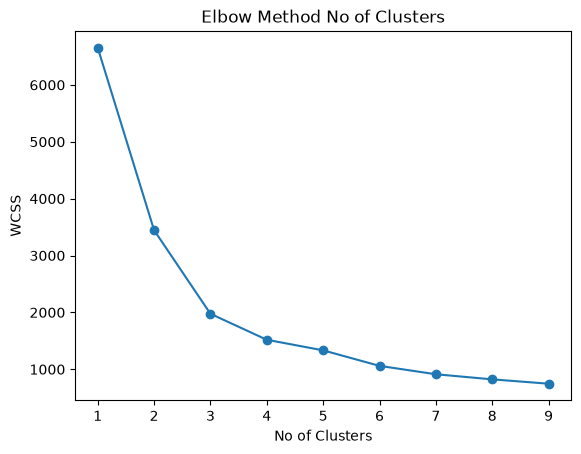

In [17]:
##### Step 4: Applying Elbow Method

## This helps you choose how many clusters to use
## The measure is usually called inertia or WCSS (Within- Cluster Sum of Squares). It adds up how far each point sits from the centre of the cluster
## Each time you add a cluster the value drops but where you make your decision on the number of clusters is where the line begins to curve
WCCS = []

for k in range (1,10):
    kmeans = KMeans(n_clusters=k)
    label = kmeans.fit(X_PCA_Scaled)
    WCCS.append(label.inertia_)


plt.plot(range(1,10),WCCS,marker='o')
plt.xlabel('No of Clusters')
plt.ylabel('WCSS')
plt.title ('Elbow Method No of Clusters')

In [18]:
#### Step 5: Combining All Indicators together like WCCS, Silhouette Score & Davies Bouldin Score when deciding best Cluster to use with PCA Applied

### Silhouette Score: This score goes from 0-1. It measures how likely you belong to the group. The higher the score the better
### Davis Bouldin Score: How well one cluster is separated from the other

results = []

for k in range (2,11):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(X_PCA_Scaled)
    WCCS = kmeans.inertia_

    Silhouette_Score = silhouette_score(X_PCA_Scaled,labels)

    Davies_Bouldin_Score = davies_bouldin_score(X_PCA_Scaled,labels)

    results.append({'Clusters': k,
                     'WCCS':round(WCCS,2),
                     'Silhouette_Score':round(Silhouette_Score,4),
                     'Davis Bouldin Score':round(Davies_Bouldin_Score,4)})


results_dataframe = pd.DataFrame(results)

print(results_dataframe)

   Clusters     WCCS  Silhouette_Score  Davis Bouldin Score
0         2  3445.70            0.4770               0.8552
1         3  1977.70            0.5176               0.7665
2         4  1518.87            0.4864               0.8022
3         5  1228.60            0.4332               0.8102
4         6  1059.85            0.4407               0.8119
5         7   912.35            0.4153               0.8506
6         8   820.73            0.3961               0.8369
7         9   748.14            0.3694               0.8828
8        10   665.17            0.3773               0.8099


In [19]:
##### Step 6: Explaining Overall Variance

print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

[0.37659704 0.23565702]
0.6122540651817773



Feature Importance - PC1
NumCatalogPurchases    0.444313
Income                 0.441710
Total_Product_Spend    0.404229
Total_Kids             0.360502
NumStorePurchases      0.347666
NumWebVisitsMonth      0.309325
NumWebPurchases        0.255562
NumDealsPurchases      0.178828
Length_of_Time         0.016089
Recency                0.003380
dtype: float64


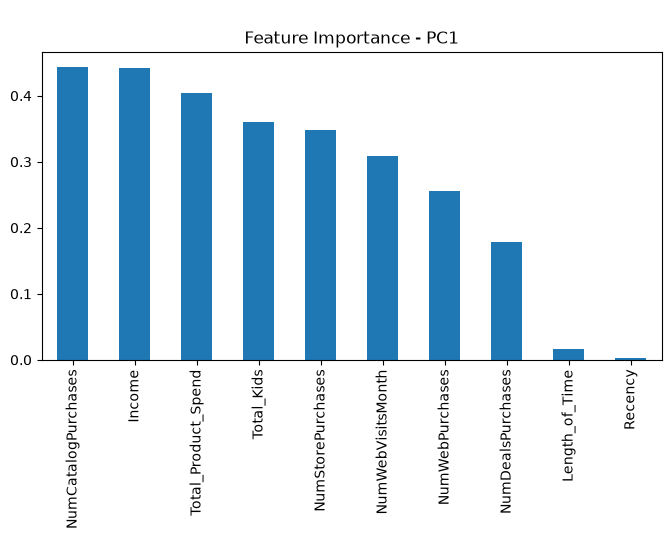


Feature Importance - PC2
NumDealsPurchases      0.825201
NumWebPurchases        0.337297
Total_Kids             0.270801
Length_of_Time         0.191781
NumStorePurchases      0.183865
NumWebVisitsMonth      0.158208
NumCatalogPurchases    0.125522
Total_Product_Spend    0.109144
Income                 0.092848
Recency                0.005938
dtype: float64


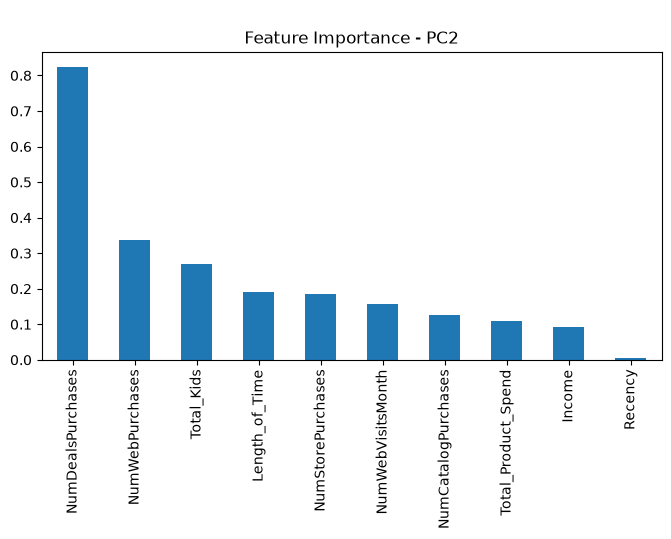

                          PC1       PC2
NumDealsPurchases   -0.178828  0.825201
NumWebPurchases      0.255562  0.337297
Total_Kids          -0.360502  0.270801
Length_of_Time       0.016089  0.191781
NumStorePurchases    0.347666  0.183865
NumWebVisitsMonth   -0.309325  0.158208
NumCatalogPurchases  0.444313  0.125522
Total_Product_Spend  0.404229  0.109144
Income               0.441710  0.092848
Recency              0.003380  0.005938


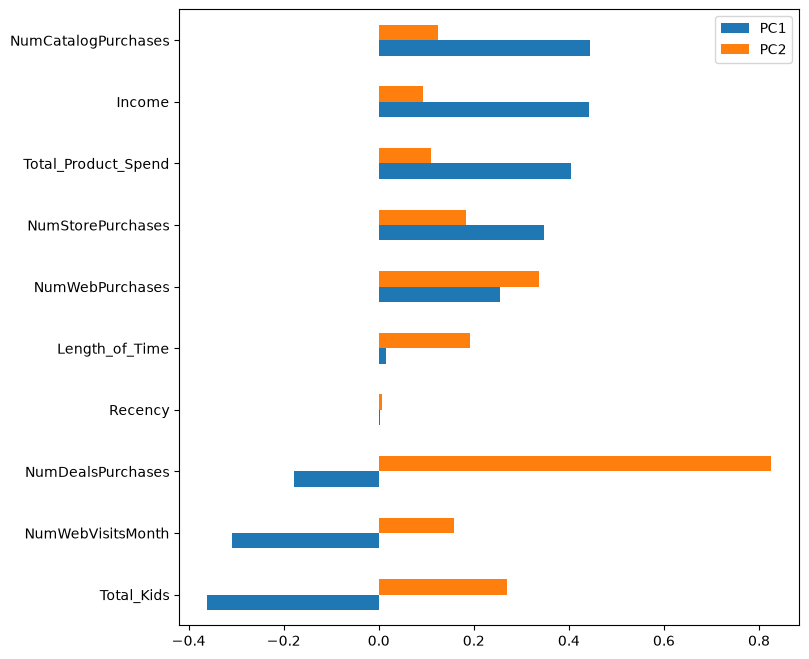

In [20]:
#### Step 7: Explaining which variables cause most variance


for i in range(2):
    Importance = pd.Series(abs(pca.components_[i]),index=X.columns).sort_values(ascending=False)
    print(f"\nFeature Importance - PC{i+1}")
    print(Importance)
    
    Importance.plot(kind='bar',figsize=(8,4))
    plt.title(f"\nFeature Importance - PC{i+1}")
    plt.show()




loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print(loadings[['PC1', 'PC2']].sort_values(
    by='PC2',
    key=abs,
    ascending=False
))


loadings.sort_values("PC1").plot.barh(figsize=(8, 8));